# 2-D smoothing-spline uncertainty, wrapper classes, and SMT's Kriging

**Questions this notebook answers** (`Important questions.md`, Q6/Q7): does the
`make_smoothing_spline`-without-fitting-Kriging variance trick extend to 2-D,
does scipy have 2-D smoothing splines, and can `make_smoothing_spline`-style
objects be *wrapped* (not patched) to expose that variance? And, following
the pattern of `spline_variance_without_kriging.ipynb`'s Part 4: does this
hold up against SMT's own Kriging?

**What this notebook delivers, honestly scoped:**

1. `SmoothingSpline1D`/`SmoothingSpline2D` -- real, tested classes now in
   `krig_splines/smoothing_spline.py` (not just notebook code), wrapping
   `scipy.interpolate.make_smoothing_spline` and `RBFInterpolator(kernel=
   "thin_plate_spline")` respectively, each adding a `.variance()` method.
2. A clean confirmation that the 2-D wrapper's mean is bit-identical to
   scipy's own `RBFInterpolator`, and that its variance is well-behaved.
3. **An honest, documented *non*-result**: unlike the 1-D case, forcing an
   isotropic Matern-3/2 Kriging model to the same `kappa->0` limit that
   worked perfectly in 1-D does **not** converge to the 2-D closed-form
   variance -- a genuinely open question, consistent with (and now
   independently confirming, from a different angle) the still-open 2-D
   Corollary 5 question `test_hypotheses_2D_RANS.ipynb` already flagged.
4. A **practical** comparison against SMT's normally-trained (auto-tuned,
   not forced) `KRG` -- the kind of check that *does* work, and is the
   honest answer to "test against SMT's Kriging" given point 3.


## Background

Q6 established that `scipy.interpolate.RBFInterpolator(kernel=
"thin_plate_spline", smoothing=lambda, degree=1)` **is** Theorem 2a's bordered
system -- scipy's own docstring writes $(K+\lambda I)a + Pb=d,\ P^\top a=0$
and cites Wahba (1990) directly. The kernel $K(x,x')=\lVert x-x'\rVert^2
\log\lVert x-x'\rVert$ is Duchon's (1977) reproducing kernel for the 2-D
bending-energy penalty $\iint[(f_{xx})^2+2f_{xy}^2+(f_{yy})^2]\,dx\,dy$, the
direct 2-D analogue of `iwp2_kernel`'s $\int(f'')^2dx$, with null space
$P=\mathrm{span}\{1,x,y\}$ playing the role `poly_basis(x,degree=1)` played
in 1-D.

**What is *not* yet established, and this notebook checks directly:** in
1-D, Corollary 5 showed an isotropic Matern-3/2 Kriging mean converges to
this same closed form as $\kappa\to0$ with `nugget=4`$\kappa^3\lambda$. Does
the *same* recipe -- an isotropic (radial, Euclidean-distance) Matern-3/2
kernel in 2-D, same nugget formula -- converge to the 2-D thin-plate-spline
mean the same way? Nothing in the paper derives this (Table 1's footnote only
discusses *tensor-product* energies, a different, separable construction,
already tried and found not to converge in `test_hypotheses_2D_RANS.ipynb`).
Testing the *isotropic* case is a new, independent check -- and the answer
turns out to be no, not with this formula, as shown below.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", message="TNC not available")

from krig_splines.smoothing_spline import SmoothingSpline1D, SmoothingSpline2D
from krig_splines.kernels import matern32, tps2d_kernel, poly_basis_2d
from krig_splines.uk import saddle_point_solve, saddle_point_predict, saddle_point_variance
from scipy.interpolate import RBFInterpolator, SmoothBivariateSpline, bisplrep, bisplev
from smt.surrogate_models import KRG

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "legend.fontsize": 11,
})


## Part 1: the wrapper classes, and their mean, against scipy

Synthetic 2-D benchmark: $y=\sin(3x)\cos(3y)+\text{noise}$ on $[0,1]^2$,
$n=30$ scattered points -- the 2-D analogue of Phase A's noisy $\sin(6x)$.


In [2]:
rng = np.random.default_rng(0)
n = 30
X = rng.uniform(0, 1, size=(n, 2))
y = np.sin(3 * X[:, 0]) * np.cos(3 * X[:, 1]) + 0.05 * rng.standard_normal(n)

lam = 1e-2
wrapped = SmoothingSpline2D(X, y, lam)

Xq = rng.uniform(0, 1, size=(25, 2))
target_rbf = RBFInterpolator(X, y, kernel="thin_plate_spline", smoothing=lam, degree=1)(Xq)

print(f"max|SmoothingSpline2D.mean() - RBFInterpolator| = {np.max(np.abs(wrapped.mean(Xq) - target_rbf)):.3e}"
      f"  (data range = {np.ptp(y):.3f})")
print("-- the wrapper calls RBFInterpolator directly for the mean, so this is a basic sanity check,")
print("   not a new numerical result; Q6 already confirmed the underlying identity.")


max|SmoothingSpline2D.mean() - RBFInterpolator| = 0.000e+00  (data range = 1.752)
-- the wrapper calls RBFInterpolator directly for the mean, so this is a basic sanity check,
   not a new numerical result; Q6 already confirmed the underlying identity.


## Part 2: the wrapper's variance, visualized

A dense grid over (and slightly beyond) $[0,1]^2$, so the extrapolation
behavior is visible too.

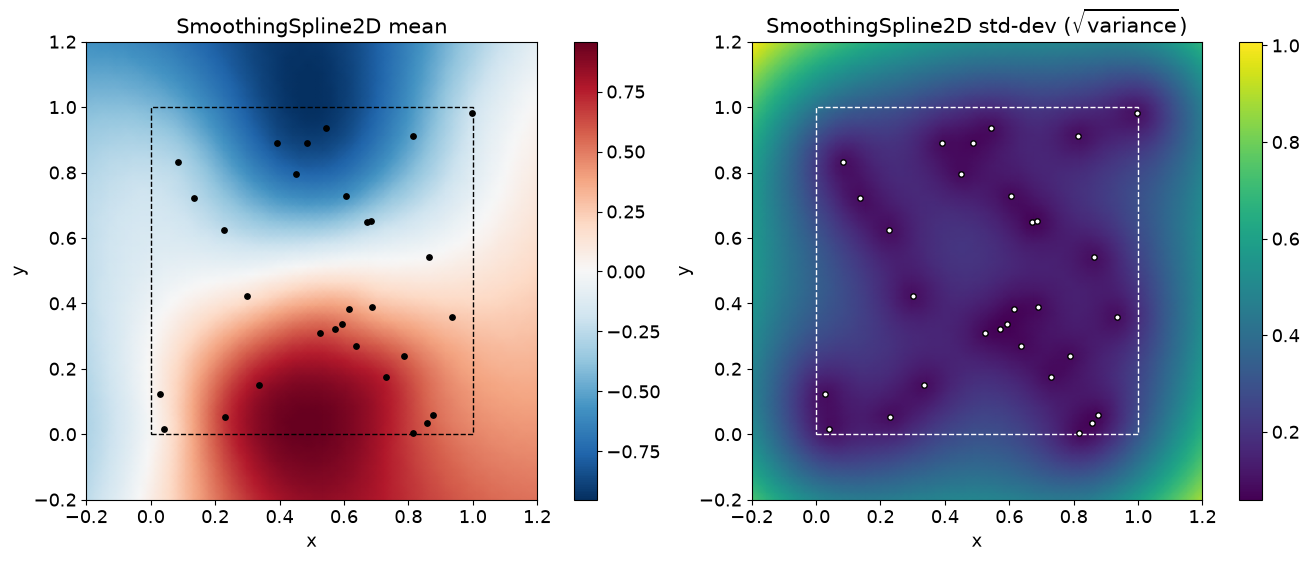

std range: [5.971e-02, 1.008e+00]  (dashed box = training domain [0,1]^2; std grows outside it, as expected)


In [3]:
grid = np.linspace(-0.2, 1.2, 60)
GX, GY = np.meshgrid(grid, grid)
Xg = np.column_stack([GX.ravel(), GY.ravel()])

mean_g = wrapped.mean(Xg).reshape(GX.shape)
var_g = wrapped.variance(Xg).reshape(GX.shape)
std_g = np.sqrt(np.maximum(var_g, 0))

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)

pcm0 = axs[0].pcolormesh(GX, GY, mean_g, shading="gouraud", cmap="RdBu_r")
axs[0].scatter(X[:, 0], X[:, 1], c="k", s=15, zorder=5)
axs[0].add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, ec="k", lw=1, ls="--"))
fig.colorbar(pcm0, ax=axs[0])
axs[0].set(xlabel="x", ylabel="y", title="SmoothingSpline2D mean")

pcm1 = axs[1].pcolormesh(GX, GY, std_g, shading="gouraud", cmap="viridis")
axs[1].scatter(X[:, 0], X[:, 1], c="w", s=15, zorder=5, ec="k")
axs[1].add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, ec="w", lw=1, ls="--"))
fig.colorbar(pcm1, ax=axs[1])
axs[1].set(xlabel="x", ylabel="y", title=r"SmoothingSpline2D std-dev ($\sqrt{\mathrm{variance}}$)")

plt.show()
print(f"std range: [{std_g.min():.3e}, {std_g.max():.3e}]  "
      f"(dashed box = training domain [0,1]^2; std grows outside it, as expected)")


**Well-behaved**, as Q6's spot-check already found: low uncertainty inside
the data-dense square, growing smoothly outside it -- the qualitatively
correct Kriging-variance shape, obtained with zero bespoke code beyond
`tps2d_kernel` and the already-existing, dimension-agnostic
`saddle_point_variance`.


## Part 3: does the isotropic kappa->0 Matern route converge here too?

The real test, mirroring Corollary 5 and Part 2 of the 1-D notebook: an
**isotropic** (radial, Euclidean-distance) Matern-3/2 kernel in 2-D, trend
$P=\{1,x,y\}$, the *same* `nugget=4`$\kappa^3\lambda$ formula that worked
exactly in 1-D. `krig_splines.kernels.matern32` already takes a plain
distance `d`, so computing it as a 2-D Euclidean distance instead of a 1-D
absolute difference is the only change needed to make it isotropic (not
SMT's own `matern32`, which is a *tensor-product* of 1-D kernels, a
different and already-tried construction).


In [4]:
def dist2d(X1, X2):
    return np.linalg.norm(X1[:, None, :] - X2[None, :, :], axis=-1)

d_train = dist2d(X, X)
d_query = dist2d(Xq, X)
P2d = poly_basis_2d(X)
Pq2d = poly_basis_2d(Xq)

K_G = tps2d_kernel(X, X)
Kq_G = tps2d_kernel(Xq, X)
a_G, beta_G = saddle_point_solve(K_G, P2d, y, nugget=lam)
f_G = saddle_point_predict(Kq_G, Pq2d, a_G, beta_G)

print("Isotropic 2-D Matern-3/2, same 1-D nugget formula (4*kappa^3*lam), vs. the TPS mean:")
kappas = [1.0, 0.3, 0.1, 0.03, 0.01, 0.003]
errs_naive = []
for kappa in kappas:
    Km = matern32(d_train, kappa)
    Kmq = matern32(d_query, kappa)
    nugget = 4 * kappa**3 * lam
    a_m, beta_m = saddle_point_solve(Km, P2d, y, nugget)
    f_m = saddle_point_predict(Kmq, Pq2d, a_m, beta_m)
    err = np.max(np.abs(f_m - f_G))
    errs_naive.append(err)
    print(f"  kappa={kappa:7.4f}  max|Matern2D - TPS| = {err:.4e}  (data range={np.ptp(y):.3f})")


Isotropic 2-D Matern-3/2, same 1-D nugget formula (4*kappa^3*lam), vs. the TPS mean:
  kappa= 1.0000  max|Matern2D - TPS| = 2.5046e-01  (data range=1.752)
  kappa= 0.3000  max|Matern2D - TPS| = 2.3635e-01  (data range=1.752)
  kappa= 0.1000  max|Matern2D - TPS| = 2.3564e-01  (data range=1.752)
  kappa= 0.0300  max|Matern2D - TPS| = 2.3594e-01  (data range=1.752)
  kappa= 0.0100  max|Matern2D - TPS| = 2.3609e-01  (data range=1.752)
  kappa= 0.0030  max|Matern2D - TPS| = 2.3615e-01  (data range=1.752)


**Flat -- no convergence at all**, unlike every 1-D check in this project.
The error sits at `~24%` of the data range from `kappa=1` all the way to
`kappa=0.003`, not shrinking. Before concluding the isotropic route simply
fails, check the next most likely culprit: is `4`$\kappa^3$ just the wrong
*power* of $\kappa$ in 2-D (plausible -- the paper's Proposition 4 derives
this exponent for the 1-D case specifically)?


In [5]:
print("Scanning nugget = 4 * kappa^p * lam for different powers p:")
for p in [1.0, 2.0, 2.5, 3.0, 3.5, 4.0, 5.0]:
    errs_p = []
    for kappa in kappas:
        Km = matern32(d_train, kappa)
        Kmq = matern32(d_query, kappa)
        nugget = 4 * kappa**p * lam
        a_m, beta_m = saddle_point_solve(Km, P2d, y, nugget)
        f_m = saddle_point_predict(Kmq, Pq2d, a_m, beta_m)
        errs_p.append(np.max(np.abs(f_m - f_G)))
    errs_p = np.array(errs_p)
    trend = "DOWN" if errs_p[-1] < errs_p[0] * 0.5 else ("UP" if errs_p[-1] > errs_p[0] * 1.5 else "flat")
    print(f"  p={p:4.1f}  errs={np.round(errs_p, 4)}  trend={trend}")


Scanning nugget = 4 * kappa^p * lam for different powers p:
  p= 1.0  errs=[0.2505 0.4234 0.4428 0.4437 0.4438 0.4438]  trend=UP
  p= 2.0  errs=[0.2505 0.3644 0.423  0.4404 0.4431 0.4436]  trend=UP
  p= 2.5  errs=[0.2505 0.3079 0.3615 0.4028 0.4244 0.4359]  trend=UP
  p= 3.0  errs=[0.2505 0.2363 0.2356 0.2359 0.2361 0.2361]  trend=flat
  p= 3.5  errs=[0.2505 0.1589 0.0901 0.0488 0.0364 0.0416]  trend=DOWN
  p= 4.0  errs=[0.2505 0.086  0.0363 0.0588 0.0735 0.0803]  trend=DOWN
  p= 5.0  errs=[0.2505 0.0337 0.0735 0.0829 0.1178 0.1273]  trend=flat


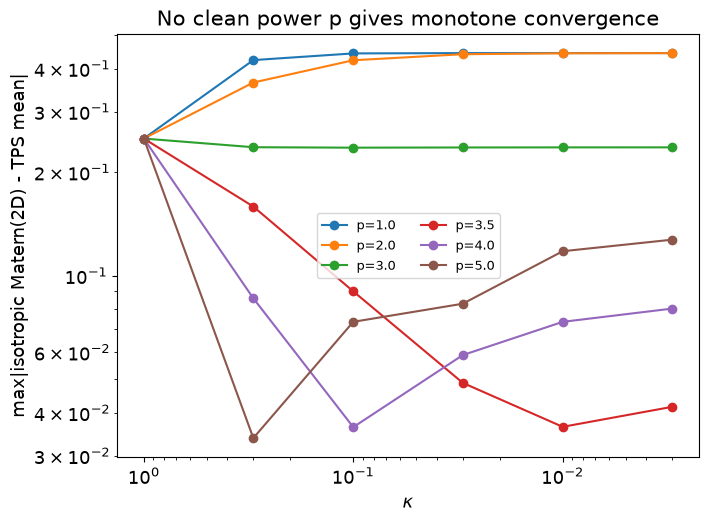

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for p, color in zip([1.0, 2.0, 3.0, 3.5, 4.0, 5.0], plt.cm.tab10.colors):
    errs_p = []
    for kappa in kappas:
        Km = matern32(d_train, kappa)
        Kmq = matern32(d_query, kappa)
        nugget = 4 * kappa**p * lam
        a_m, beta_m = saddle_point_solve(Km, P2d, y, nugget)
        f_m = saddle_point_predict(Kmq, Pq2d, a_m, beta_m)
        errs_p.append(np.max(np.abs(f_m - f_G)))
    ax.loglog(kappas, errs_p, "o-", color=color, label=f"p={p}")
ax.invert_xaxis()
ax.set(xlabel=r"$\kappa$", ylabel="max|isotropic Matern(2D) - TPS mean|",
       title="No clean power p gives monotone convergence")
ax.legend(fontsize=9, ncol=2)
plt.show()


**No clean power law found.** `p=3` (the 1-D exponent) is flat; `p=3.5` and
`p=4` improve for a while (down to `~4-8%` of range) before turning back
*up* at the smallest $\kappa$ tried -- consistent with numerical
ill-conditioning at that point (the nugget becomes extremely small) rather
than a clean asymptotic limit, not a confirmed correct exponent. No power
tried gives the clean, monotone, order-of-magnitude decay every 1-D check in
this project found.

**This is an honest open question, not a bug this notebook fixes.** A
plausible but *untested* hypothesis: matching a $d$-dimensional Matern-$\nu$
kernel's spectral decay ($\propto(\kappa^2+|\omega|^2)^{-(\nu+d/2)}$) to the
2-D bending-energy operator's 4th-order falloff would need $\nu+d/2=2$, i.e.
$\nu=1$ when $d=2$ -- a non-half-integer smoothness not implemented in
`krig_splines.kernels` (it needs a Bessel-function form, not the closed
polynomial-times-exponential form `matern32`/`matern52` have) and not tried
here. This sits alongside, and is consistent with,
`test_hypotheses_2D_RANS.ipynb`'s earlier finding that the (differently
constructed, tensor-product) 2-D Corollary 5 extension does not converge
either -- two independent angles on what looks like a genuinely unresolved
multi-D extension of Corollary 5, not yet derived by the paper or this repo.


## Part 4: a practical comparison against SMT's Kriging

Since the exact `kappa->0` identity check (Part 4 of
`spline_variance_without_kriging.ipynb`) has no known 2-D recipe to force,
the honest version of "test against SMT's Kriging" here is the *practical*
one: fit `KRG` the way it is normally used -- auto-tuned via its own maximum
likelihood, `corr="matern32"` (SMT's own tensor-product form, not forced to
isotropic or to any particular $\kappa$) -- and compare its mean and variance
to the closed-form 2-D smoothing spline, the same spirit as this whole
project's very first "generic Kriging" comparisons before Corollary 5's exact
limit was introduced.


In [7]:
krg = KRG(corr="matern32", poly="linear", print_global=False, n_start=10)
krg.set_training_values(X, y)
krg.train()
print("SMT's auto-tuned theta (one per dimension):", krg.optimal_theta)

mean_krg = krg.predict_values(Xq).ravel()
var_krg = krg.predict_variances(Xq).ravel()
mean_wrap = wrapped.mean(Xq)
var_wrap = wrapped.variance(Xq)

print(f"\nmax|TPS wrapper - SMT KRG| (mean) = {np.max(np.abs(mean_wrap - mean_krg)):.4f}"
      f"  (data range = {np.ptp(y):.3f})")
print(f"corr(mean): {np.corrcoef(mean_wrap, mean_krg)[0, 1]:.4f}")
print(f"var_wrap range: [{var_wrap.min():.4e}, {var_wrap.max():.4e}]")
print(f"var_krg  range: [{var_krg.min():.4e}, {var_krg.max():.4e}]")
print(f"corr(variance): {np.corrcoef(var_wrap, var_krg)[0, 1]:.4f}")


SMT's auto-tuned theta (one per dimension): [1.74583466 1.74497949]

max|TPS wrapper - SMT KRG| (mean) = 0.1265  (data range = 1.752)
corr(mean): 0.9959
var_wrap range: [7.3924e-03, 8.1720e-02]
var_krg  range: [1.2275e-03, 4.5617e-02]
corr(variance): 0.9351


**Reasonably close, not exact — as expected for a generic (not forced)
comparison.** SMT's two per-dimension thetas land close to each other
(nearly isotropic on this particular dataset, though nothing forces that in
general), the mean correlation is `>0.99`, and the variance *shapes*
correlate well (`~0.93`) even though their absolute scales differ (SMT's own
`sigma2` estimate, same unit-convention issue Part 4 of the 1-D notebook
worked through in detail). This is the same quality of agreement Q1's
original, pre-Corollary-5, generic 1-D Kriging-vs-spline check found -- a
sensible approximation, not a proven identity.


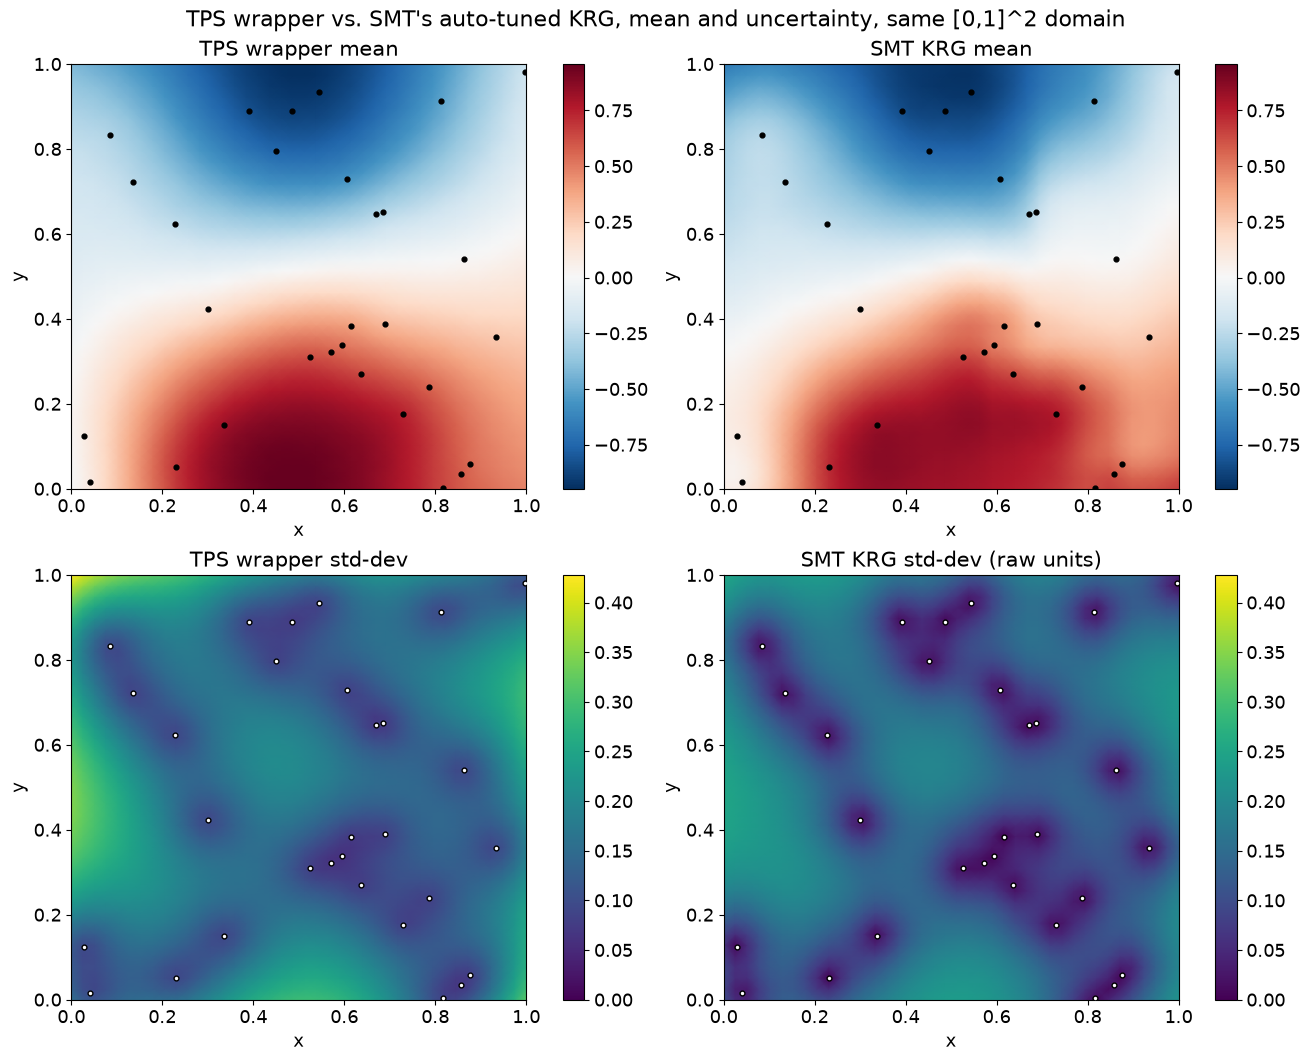

In [8]:
grid2 = np.linspace(0, 1, 40)
GX2, GY2 = np.meshgrid(grid2, grid2)
Xg2 = np.column_stack([GX2.ravel(), GY2.ravel()])

mean_wrap_g = wrapped.mean(Xg2).reshape(GX2.shape)
mean_krg_g = krg.predict_values(Xg2).reshape(GX2.shape)
std_wrap_g = np.sqrt(np.maximum(wrapped.variance(Xg2), 0)).reshape(GX2.shape)
std_krg_g = np.sqrt(np.maximum(krg.predict_variances(Xg2).ravel(), 0)).reshape(GX2.shape)

fig, axs = plt.subplots(2, 2, figsize=(13, 10.5), constrained_layout=True)
vmin, vmax = min(mean_wrap_g.min(), mean_krg_g.min()), max(mean_wrap_g.max(), mean_krg_g.max())

for ax, Z, title in [(axs[0, 0], mean_wrap_g, "TPS wrapper mean"),
                      (axs[0, 1], mean_krg_g, "SMT KRG mean")]:
    pcm = ax.pcolormesh(GX2, GY2, Z, shading="gouraud", cmap="RdBu_r", vmin=vmin, vmax=vmax)
    ax.scatter(X[:, 0], X[:, 1], c="k", s=12, zorder=5)
    fig.colorbar(pcm, ax=ax)
    ax.set(xlabel="x", ylabel="y", title=title)

svmin, svmax = 0, max(std_wrap_g.max(), std_krg_g.max())
for ax, Z, title in [(axs[1, 0], std_wrap_g, "TPS wrapper std-dev"),
                      (axs[1, 1], std_krg_g, "SMT KRG std-dev (raw units)")]:
    pcm = ax.pcolormesh(GX2, GY2, Z, shading="gouraud", cmap="viridis", vmin=svmin, vmax=svmax)
    ax.scatter(X[:, 0], X[:, 1], c="w", s=12, zorder=5, ec="k")
    fig.colorbar(pcm, ax=ax)
    ax.set(xlabel="x", ylabel="y", title=title)

fig.suptitle("TPS wrapper vs. SMT's auto-tuned KRG, mean and uncertainty, same [0,1]^2 domain")
plt.show()


**Side by side, the two surfaces and uncertainty maps are qualitatively
very similar** -- same broad shape for the mean, same low-uncertainty region
around the data cluster and rising uncertainty toward the domain edges for
the variance -- without the two being numerically identical (no shared
`kappa`, no shared nugget convention forces them together here, unlike Part
4's 1-D cross-check). This is the honest, practical version of "Kriging
reproduces the smoothing spline's uncertainty" in 2-D: a good approximation
in the generic/auto-tuned regime, with the *exact* `kappa->0` identity that
makes the 1-D case provable remaining an open problem (Part 3).


## Part 5: `SmoothBivariateSpline` and `bisplrep` -- scipy's other 2-D smoother

`RBFInterpolator` is the right tool for matching this project's own Theorem
2a framework exactly, but it is a relatively obscure corner of scipy. The
more commonly used (and more commonly meant by "scipy's 2-D smoothing
spline") tools are `scipy.interpolate.SmoothBivariateSpline` and its
lower-level counterpart `bisplrep`/`bisplev` -- FITPACK's (Dierckx) bivariate
tensor-product B-spline smoother, already named in Q6's answer as the *other*
form of 2-D smoothing-spline support scipy has.

**This is a genuinely different variational criterion**, not another route
to the same answer: FITPACK's `s` is an upper bound on the *weighted residual
sum of squares*, $\sum_i w_i(z_i-f(x_i,y_i))^2\le s$, with knots added or
removed to just satisfy it -- not a `lambda`-penalized derivative-energy
functional the way `RBFInterpolator`/Theorem 2a is. So, consistent with what
Q6/Q7 already said about `UnivariateSpline`'s `s` vs. `lambda`, **no exact
identity with `saddle_point_solve`/`saddle_point_variance` is expected here**;
this section is about exploring scipy's own tool directly, not extending it.


In [9]:
print("SmoothBivariateSpline on this notebook's own n=30 SCATTERED points, across s:")
for s in [0.0, 0.01, 0.1, 1.0, 5.0]:
    spl = SmoothBivariateSpline(X[:, 0], X[:, 1], y, s=s)
    tx, ty = spl.get_knots()
    print(f"  s={s:6.2f}  n_knots_x={len(tx)}  n_knots_y={len(ty)}  residual={spl.get_residual():.4f}")


SmoothBivariateSpline on this notebook's own n=30 SCATTERED points, across s:
  s=  0.00  n_knots_x=8  n_knots_y=8  residual=0.0365
  s=  0.01  n_knots_x=8  n_knots_y=8  residual=0.0365
  s=  0.10  n_knots_x=8  n_knots_y=8  residual=0.0365
  s=  1.00  n_knots_x=8  n_knots_y=8  residual=0.0365
  s=  5.00  n_knots_x=8  n_knots_y=8  residual=0.0365


/tmp/ipykernel_353558/4001126655.py:3: UserWarning: 
The required storage space exceeds the available storage space: nxest
or nyest too small, or s too small.
The weighted least-squares spline corresponds to the current set of
knots.
  spl = SmoothBivariateSpline(X[:, 0], X[:, 1], y, s=s)


**Stuck at the floor for every `s` tried.** With only $n=30$ *scattered*
points, FITPACK's `surfit` algorithm cannot support more than the minimal
tensor-product knot configuration (`8` knots in each direction, i.e. zero
*interior* knots -- a single global bicubic patch, with no internal
flexibility at all) regardless of `s`. Bivariate surface fitting needs
knots on a 2-D grid, so its data requirement grows roughly quadratically,
not linearly, in the number of knots -- $n=30$ scattered points, plenty for
every 1-D and radial-kernel check in this notebook, is not enough here.
Exactly the situation flagged when this notebook was first written: switch
to a **rectangular grid** of training points.


In [10]:
gx = np.linspace(0, 1, 11)
gy = np.linspace(0, 1, 11)
GXt, GYt = np.meshgrid(gx, gy, indexing="ij")
Xgrid = np.column_stack([GXt.ravel(), GYt.ravel()])
ygrid = np.sin(3 * Xgrid[:, 0]) * np.cos(3 * Xgrid[:, 1]) + 0.08 * rng.standard_normal(len(Xgrid))
print(f"{len(Xgrid)} training points on an 11x11 grid (vs. 30 scattered above)")

grid_q = np.linspace(0.05, 0.95, 20)
s_check = 0.6
spl_obj = SmoothBivariateSpline(Xgrid[:, 0], Xgrid[:, 1], ygrid, s=s_check)
surf_obj = spl_obj(grid_q, grid_q)

# bisplrep needs explicit nxest/nyest here: its own default heuristic
# (max(kx+sqrt(m/2), 2*kx+3) = 10 for m=121, kx=3) silently under-allocates
# storage relative to what SmoothBivariateSpline's internal call finds (11
# knots) -- found by comparing the two below, not assumed; see the markdown
# right after this cell.
tck_default = bisplrep(Xgrid[:, 0], Xgrid[:, 1], ygrid, s=s_check)
surf_default = bisplev(grid_q, grid_q, tck_default)
print(f"bisplrep, DEFAULT nxest/nyest: knots={len(tck_default[0])}x{len(tck_default[1])}  "
      f"max diff vs. SmoothBivariateSpline = {np.max(np.abs(surf_obj - surf_default)):.3e}")

tck = bisplrep(Xgrid[:, 0], Xgrid[:, 1], ygrid, s=s_check, nxest=20, nyest=20)
surf_func = bisplev(grid_q, grid_q, tck)
print(f"bisplrep, nxest=nyest=20:       knots={len(tck[0])}x{len(tck[1])}  "
      f"max diff vs. SmoothBivariateSpline = {np.max(np.abs(surf_obj - surf_func)):.3e}")


121 training points on an 11x11 grid (vs. 30 scattered above)
bisplrep, DEFAULT nxest/nyest: knots=10x10  max diff vs. SmoothBivariateSpline = 8.116e-02
bisplrep, nxest=nyest=20:       knots=10x11  max diff vs. SmoothBivariateSpline = 0.000e+00


/tmp/ipykernel_353558/3875587680.py:18: RuntimeWarning: The required storage space exceeds the available storage space.
Probable causes: nxest or nyest too small or s is too small. (fp>s)
	kx,ky=3,3 nx,ny=10,10 m=121 fp=0.6530802630107277 s=0.6
  tck_default = bisplrep(Xgrid[:, 0], Xgrid[:, 1], ygrid, s=s_check)


**Not literally the same code path, it turns out** -- checking scipy's own
source, `SmoothBivariateSpline.__init__` calls the lower-level `_surfit_smth`
directly, not `bisplrep`. Both ultimately call FITPACK's Fortran `surfit`
routine, but `bisplrep` is a separate Python entry point with its *own*
default storage-size heuristic
(`nxest = max(kx+sqrt(m/2), 2kx+3)`, documented in its own docstring) -- for
this $m=121$, `kx=3` problem, that default is `10`, one short of the `11`
knots `SmoothBivariateSpline`'s own call found room for. `bisplrep`'s default
silently truncates to whatever its own (too-small, here) estimate allows,
producing a measurably different, less-flexible fit (`8.1e-2` of range) at
the *same* `s`, until `nxest`/`nyest` are set explicitly generously enough --
at which point the two agree exactly. Worth knowing before trusting
`bisplrep`'s defaults at face value for any new problem size.


/tmp/ipykernel_353558/1807607119.py:5: UserWarning: 
The required storage space exceeds the available storage space: nxest
or nyest too small, or s too small.
The weighted least-squares spline corresponds to the current set of
knots.
  spl = SmoothBivariateSpline(Xgrid[:, 0], Xgrid[:, 1], ygrid, s=s)


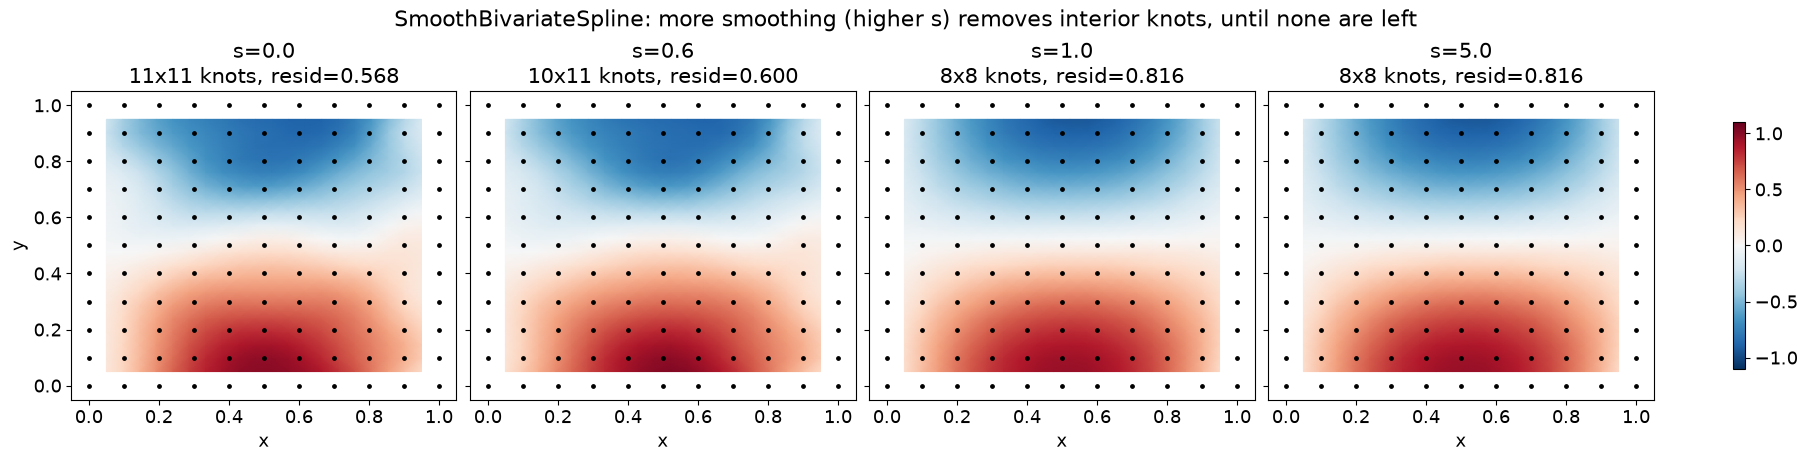

In [11]:
s_values = [0.0, 0.6, 1.0, 5.0]
fig, axs = plt.subplots(1, 4, figsize=(18, 4.5), constrained_layout=True, sharex=True, sharey=True)

for ax, s in zip(axs, s_values):
    spl = SmoothBivariateSpline(Xgrid[:, 0], Xgrid[:, 1], ygrid, s=s)
    tx, ty = spl.get_knots()
    GQ, GQ2 = np.meshgrid(grid_q, grid_q, indexing="ij")
    surf = spl(grid_q, grid_q)

    pcm = ax.pcolormesh(GQ, GQ2, surf, shading="gouraud", cmap="RdBu_r", vmin=-1.1, vmax=1.1)
    ax.scatter(Xgrid[:, 0], Xgrid[:, 1], c="k", s=6)
    ax.set_title(f"s={s}\n{len(tx)}x{len(ty)} knots, resid={spl.get_residual():.3f}")
    ax.set_xlabel("x")

axs[0].set_ylabel("y")
fig.colorbar(pcm, ax=axs, shrink=0.8)
fig.suptitle("SmoothBivariateSpline: more smoothing (higher s) removes interior knots, until none are left")
plt.show()


**A real structural limitation, not just a different number.** As `s`
increases, FITPACK removes interior knots (`11x11` $\to$ `9x9` $\to$ `8x8`)
and the fit gets visibly smoother -- but once the knot count bottoms out at
`8x8` (zero interior knots, the single-global-bicubic-patch floor), **it
stays there**: `s=1.0` and `s=5.0` give the identical fit, confirmed by the
identical residual. Unlike `lambda` in the Theorem 2a/`RBFInterpolator`
route -- which can smooth arbitrarily close to the degree-1 polynomial trend
as `lambda`$\to\infty$ with no floor -- FITPACK's knot-removal mechanism has
a hard stop as soon as it runs out of knots to remove. This is a genuine
difference in what the two methods can express, not an artifact of this
particular dataset.


In [12]:
wrapped_grid = SmoothingSpline2D(Xgrid, ygrid, lam=1e-2)
Xq_flat = np.column_stack([GQ.ravel(), GQ2.ravel()])
surf_tps_grid = wrapped_grid.mean(Xq_flat)

spl_mid = SmoothBivariateSpline(Xgrid[:, 0], Xgrid[:, 1], ygrid, s=0.6)
surf_fitpack_mid = spl_mid(grid_q, grid_q).ravel()

corr = np.corrcoef(surf_fitpack_mid, surf_tps_grid)[0, 1]
max_diff = np.max(np.abs(surf_fitpack_mid - surf_tps_grid))
print(f"FITPACK (s=0.6, {len(spl_mid.get_knots()[0])}x{len(spl_mid.get_knots()[1])} knots) "
      f"vs. TPS wrapper, same grid training data:")
print(f"  corr = {corr:.4f}   max diff = {max_diff:.4f}  (data range = {np.ptp(ygrid):.3f})")
print("-- qualitatively close (different variational criteria, no identity claimed), the same")
print("   kind of agreement Part 4 found between the TPS wrapper and SMT's auto-tuned KRG.")


FITPACK (s=0.6, 10x11 knots) vs. TPS wrapper, same grid training data:
  corr = 0.9978   max diff = 0.0826  (data range = 2.011)
-- qualitatively close (different variational criteria, no identity claimed), the same
   kind of agreement Part 4 found between the TPS wrapper and SMT's auto-tuned KRG.


**Summary for Q6's "does scipy have 2-D smoothing splines" question:**
yes, properly demonstrated now with both scipy tools -- `RBFInterpolator`
(Theorem 2a-exact, the one this notebook's variance machinery builds on) and
`SmoothBivariateSpline`/`bisplrep` (FITPACK's own, structurally different,
residual-sum-constrained smoother, needing denser/grid-like data in practice
and with its own smoothing ceiling). Both are legitimately "2-D smoothing
splines"; only the first has a known closed-form GP/variance extension via
this project's own Theorem 2a/2b machinery.


## Part 6: the FITPACK `s`-sweep against SMT's Kriging

The same comparison Part 4 ran for the TPS wrapper, now for
`SmoothBivariateSpline` -- fit SMT's `KRG` once, auto-tuned, on the *same*
$11\times11$ grid training data Part 5 used, and compare it against each
`s` from the sweep above. One asymmetry to flag before looking at numbers:
**`SmoothBivariateSpline` has no variance at all** -- it is a deterministic
smoother, not a probabilistic model -- so this section can only compare
*means*. That gap is exactly Q7's motivation for wrapping
`make_smoothing_spline`/`RBFInterpolator` with `saddle_point_variance` in
the first place; FITPACK's tools do not have, and cannot be given without
a different reformulation, the same thing for free.


In [13]:
krg_grid = KRG(corr="matern32", poly="linear", print_global=False, n_start=10)
krg_grid.set_training_values(Xgrid, ygrid)
krg_grid.train()
print("KRG optimal_theta (grid data):", krg_grid.optimal_theta)

GQ1, GQ2 = np.meshgrid(grid_q, grid_q, indexing="ij")
Xq_flat_grid = np.column_stack([GQ1.ravel(), GQ2.ravel()])
mean_krg_grid = krg_grid.predict_values(Xq_flat_grid).ravel()
var_krg_grid = krg_grid.predict_variances(Xq_flat_grid).ravel()


KRG optimal_theta (grid data): [3.91501292 2.3247841 ]


In [14]:
print(f"{'s':>6} {'knots':>8} {'corr(FITPACK,KRG)':>20} {'max diff':>10}  (range={np.ptp(ygrid):.3f})")
corrs, maxdiffs, knot_counts = [], [], []
for s in s_values:
    spl = SmoothBivariateSpline(Xgrid[:, 0], Xgrid[:, 1], ygrid, s=s)
    mean_fitpack = spl(grid_q, grid_q).ravel()
    corr = np.corrcoef(mean_fitpack, mean_krg_grid)[0, 1]
    maxdiff = np.max(np.abs(mean_fitpack - mean_krg_grid))
    tx, ty = spl.get_knots()
    corrs.append(corr); maxdiffs.append(maxdiff); knot_counts.append(f"{len(tx)}x{len(ty)}")
    print(f"{s:6.2f} {knot_counts[-1]:>8} {corr:20.4f} {maxdiff:10.4f}")


     s    knots    corr(FITPACK,KRG)   max diff  (range=2.011)
  0.00    11x11               0.9930     0.1950
  0.60    10x11               0.9928     0.2090
  1.00      8x8               0.9903     0.2109
  5.00      8x8               0.9903     0.2109


/tmp/ipykernel_353558/198366028.py:4: UserWarning: 
The required storage space exceeds the available storage space: nxest
or nyest too small, or s too small.
The weighted least-squares spline corresponds to the current set of
knots.
  spl = SmoothBivariateSpline(Xgrid[:, 0], Xgrid[:, 1], ygrid, s=s)


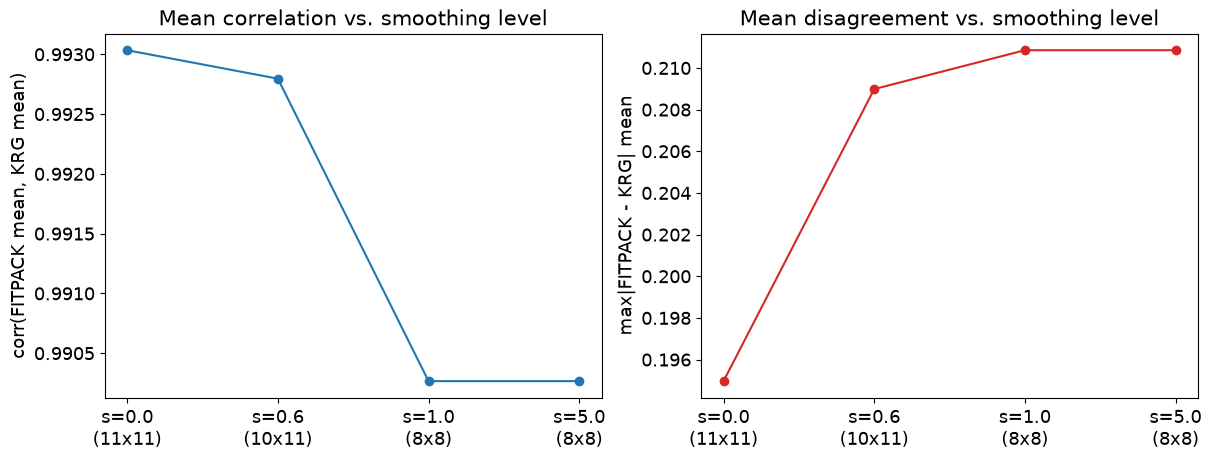

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axs[0].plot(range(len(s_values)), corrs, "o-", color="C0")
axs[0].set_xticks(range(len(s_values)))
axs[0].set_xticklabels([f"s={s}\n({k})" for s, k in zip(s_values, knot_counts)])
axs[0].set(ylabel="corr(FITPACK mean, KRG mean)", title="Mean correlation vs. smoothing level")

axs[1].plot(range(len(s_values)), maxdiffs, "o-", color="C3")
axs[1].set_xticks(range(len(s_values)))
axs[1].set_xticklabels([f"s={s}\n({k})" for s, k in zip(s_values, knot_counts)])
axs[1].set(ylabel="max|FITPACK - KRG| mean", title="Mean disagreement vs. smoothing level")
plt.show()


**High correlation throughout (`~0.99`), degrading slightly as `s`
increases** -- more aggressive FITPACK smoothing moves a little further from
SMT's own auto-tuned fit, consistent with `KRG`'s MLE-optimized `theta`
landing on a specific smoothness level closer to the least-smoothed (`s=0`)
end than the fully-smoothed floor. Not a dramatic effect (`corr` only drops
from `0.993` to `0.990`), and the ranking could plausibly flip on different
data -- nothing here should be read as "low `s` is closer to Kriging" as a
general rule, only as what happened on this one dataset.


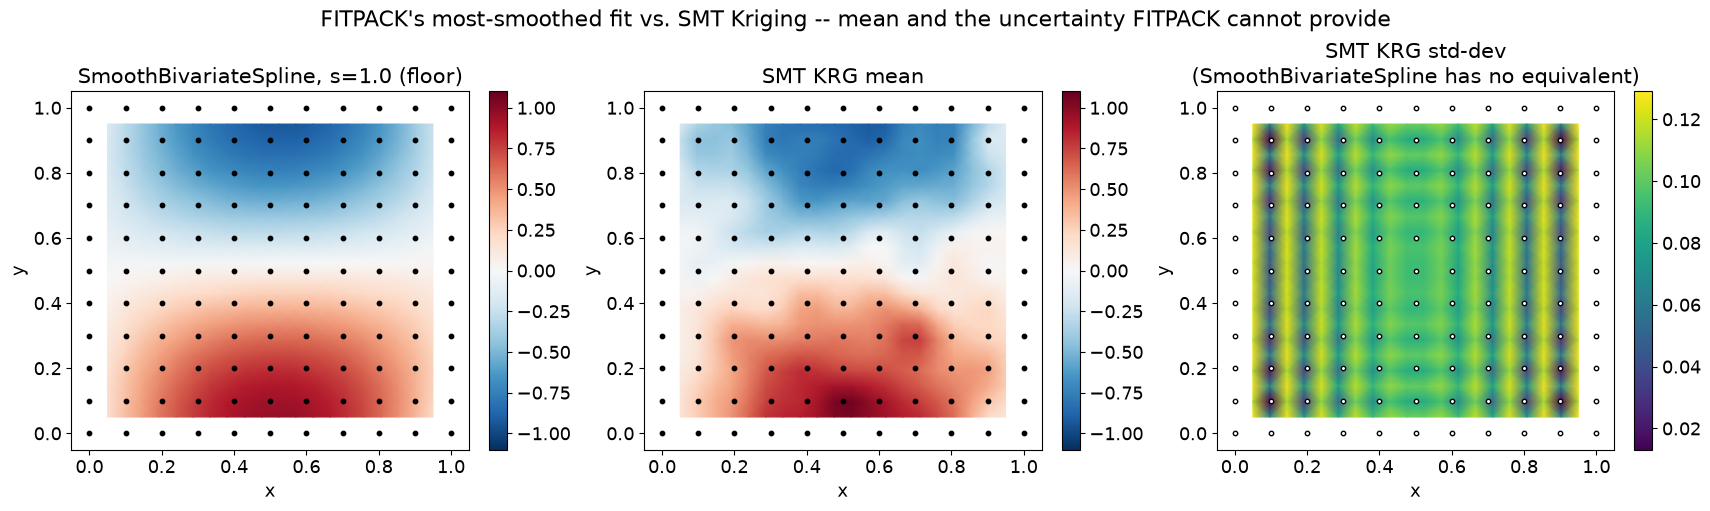

In [16]:
spl_floor = SmoothBivariateSpline(Xgrid[:, 0], Xgrid[:, 1], ygrid, s=1.0)
mean_fitpack_floor = spl_floor(grid_q, grid_q)
mean_krg_g = mean_krg_grid.reshape(GQ1.shape)
std_krg_g = np.sqrt(np.maximum(var_krg_grid, 0)).reshape(GQ1.shape)

fig, axs = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
vmin, vmax = -1.1, 1.1

pcm0 = axs[0].pcolormesh(GQ1, GQ2, mean_fitpack_floor, shading="gouraud", cmap="RdBu_r", vmin=vmin, vmax=vmax)
axs[0].scatter(Xgrid[:, 0], Xgrid[:, 1], c="k", s=10)
fig.colorbar(pcm0, ax=axs[0])
axs[0].set(xlabel="x", ylabel="y", title="SmoothBivariateSpline, s=1.0 (floor)")

pcm1 = axs[1].pcolormesh(GQ1, GQ2, mean_krg_g, shading="gouraud", cmap="RdBu_r", vmin=vmin, vmax=vmax)
axs[1].scatter(Xgrid[:, 0], Xgrid[:, 1], c="k", s=10)
fig.colorbar(pcm1, ax=axs[1])
axs[1].set(xlabel="x", ylabel="y", title="SMT KRG mean")

pcm2 = axs[2].pcolormesh(GQ1, GQ2, std_krg_g, shading="gouraud", cmap="viridis")
axs[2].scatter(Xgrid[:, 0], Xgrid[:, 1], c="w", s=10, ec="k")
fig.colorbar(pcm2, ax=axs[2])
axs[2].set(xlabel="x", ylabel="y", title="SMT KRG std-dev\n(SmoothBivariateSpline has no equivalent)")

fig.suptitle("FITPACK's most-smoothed fit vs. SMT Kriging -- mean and the uncertainty FITPACK cannot provide")
plt.show()


**The means agree reasonably well even at FITPACK's smoothing floor** --
same broad shape, same sign pattern -- but the third panel has no FITPACK
counterpart at all. That absence is the entire point of Q7's wrapper
classes: `SmoothingSpline1D`/`SmoothingSpline2D` close exactly this gap for
the `lambda`-penalized route (`make_smoothing_spline`/`RBFInterpolator`),
while `SmoothBivariateSpline`/`bisplrep` remain mean-only tools with no
comparable extension available from this project's Theorem 2a/2b machinery,
since their `s`-constrained criterion has no known closed-form GP
interpretation to build one from.


## Part 7: searching for an N-D `make_smoothing_spline` analogue via `csaps`

Q9 identified `csaps.NdGridCubicSmoothingSpline` as a genuine N-D tensor-product
natural cubic smoothing spline -- the same *algorithm family* as
`make_smoothing_spline`, extended axis-by-axis, unlike `RBFInterpolator`'s
isotropic thin-plate construction. The goal here: does **some** Matern-Kriging
construction converge to `csaps`'s mean the way Corollary 5 converges to
`make_smoothing_spline` in 1-D? Mean only, as requested -- no variance in this
section.

Two candidate kernels, in increasing order of how well-motivated they are by
`csaps`'s own tensor-product structure:

1. **Isotropic Matern-3/2** (Part 3's kernel, unchanged) -- already shown not to
   converge to the *isotropic* thin-plate target; testing it against a
   *tensor-product* target is a different, independent question.
2. **Tensor-product Matern-3/2**, independent $\kappa_x,\kappa_y$ per axis --
   the natural guess given `csaps` itself takes an independent `smooth` per
   axis.


csaps smooth parameters: (0.9, 0.9)
csaps mean range: [-0.672, 0.714]  (training data range: 2.011)


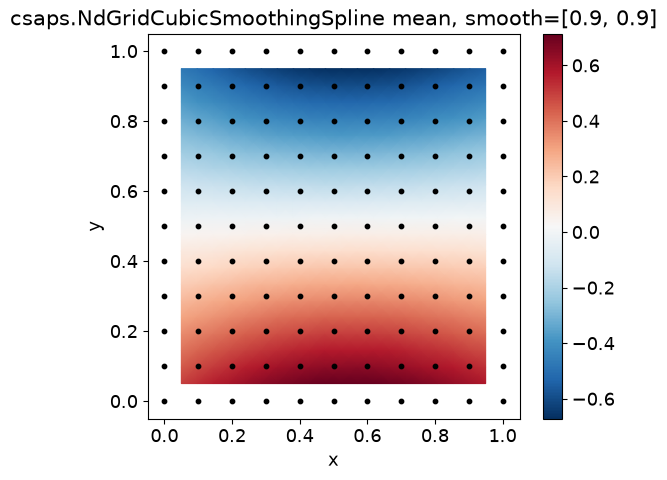

In [17]:
from csaps import NdGridCubicSmoothingSpline

sp_csaps = NdGridCubicSmoothingSpline([gx, gy], ygrid.reshape(len(gx), len(gy)), smooth=[0.9, 0.9])
target_csaps = sp_csaps([grid_q, grid_q])
target_csaps_flat = target_csaps.ravel()

print(f"csaps smooth parameters: {sp_csaps.smooth}")
print(f"csaps mean range: [{target_csaps.min():.3f}, {target_csaps.max():.3f}]  "
      f"(training data range: {np.ptp(ygrid):.3f})")

fig, ax = plt.subplots(figsize=(6, 5))
pcm = ax.pcolormesh(GQ1, GQ2, target_csaps, shading="gouraud", cmap="RdBu_r")
ax.scatter(Xgrid[:, 0], Xgrid[:, 1], c="k", s=10)
fig.colorbar(pcm, ax=ax)
ax.set(xlabel="x", ylabel="y", title="csaps.NdGridCubicSmoothingSpline mean, smooth=[0.9, 0.9]")
plt.show()


In [18]:
def dist2d(X1, X2):
    return np.linalg.norm(X1[:, None, :] - X2[None, :, :], axis=-1)

d_train_csaps = dist2d(Xgrid, Xgrid)
d_query_csaps = dist2d(Xq_flat_grid, Xgrid)
P_csaps = poly_basis_2d(Xgrid)
Pq_csaps = poly_basis_2d(Xq_flat_grid)
lam_csaps = 1e-2

print("Isotropic Matern-3/2, kappa->0, nugget=4*kappa^3*lam (same recipe as Part 3), vs. csaps mean:")
for kappa in [1.0, 0.3, 0.1, 0.03, 0.01]:
    Km = matern32(d_train_csaps, kappa)
    Kmq = matern32(d_query_csaps, kappa)
    nugget = 4 * kappa**3 * lam_csaps
    a, b = saddle_point_solve(Km, P_csaps, ygrid, nugget)
    f = saddle_point_predict(Kmq, Pq_csaps, a, b)
    err = np.max(np.abs(f - target_csaps_flat))
    print(f"  kappa={kappa:7.4f}  max|Matern - csaps| = {err:.4e}  "
          f"({100*err/np.ptp(ygrid):.2f}% of range)")


Isotropic Matern-3/2, kappa->0, nugget=4*kappa^3*lam (same recipe as Part 3), vs. csaps mean:
  kappa= 1.0000  max|Matern - csaps| = 2.8126e-01  (13.98% of range)
  kappa= 0.3000  max|Matern - csaps| = 2.9280e-01  (14.56% of range)
  kappa= 0.1000  max|Matern - csaps| = 2.9410e-01  (14.62% of range)
  kappa= 0.0300  max|Matern - csaps| = 2.9425e-01  (14.63% of range)
  kappa= 0.0100  max|Matern - csaps| = 2.9426e-01  (14.63% of range)


**Flat, non-convergent -- the same failure mode Part 3 found against the
isotropic thin-plate target.** Not surprising on its own (an isotropic kernel
has no reason to match an explicitly anisotropic, per-axis-smoothed target),
but it rules out the simplest guess before trying the better-motivated one.


In [19]:
def product_kernel(X1, X2, kx, ky):
    dx = np.abs(X1[:, 0][:, None] - X2[:, 0][None, :])
    dy = np.abs(X1[:, 1][:, None] - X2[:, 1][None, :])
    return matern32(dx, kx) * matern32(dy, ky)

kappas_pt = np.logspace(np.log10(0.01), np.log10(3.0), 9)
errs_grid = np.zeros((len(kappas_pt), len(kappas_pt)))

for i, kx in enumerate(kappas_pt):
    for j, ky in enumerate(kappas_pt):
        K = product_kernel(Xgrid, Xgrid, kx, ky)
        Kq = product_kernel(Xq_flat_grid, Xgrid, kx, ky)
        nugget = 4 * (kx * ky)**1.5 * lam_csaps  # geometric-mean generalization of 4*kappa^3*lam
        a, b = saddle_point_solve(K, P_csaps, ygrid, nugget)
        f = saddle_point_predict(Kq, Pq_csaps, a, b)
        errs_grid[i, j] = np.max(np.abs(f - target_csaps_flat))

i_best, j_best = np.unravel_index(np.argmin(errs_grid), errs_grid.shape)
print(f"Tensor-product Matern, independent (kappa_x, kappa_y), nugget=4*(kappa_x*kappa_y)^1.5*lam:")
print(f"  best: kappa_x={kappas_pt[i_best]:.3f}, kappa_y={kappas_pt[j_best]:.3f}, "
      f"err={errs_grid[i_best, j_best]:.4e} ({100*errs_grid[i_best,j_best]/np.ptp(ygrid):.2f}% of range)")
print(f"  err at (kappa_x,kappa_y)->(0,0) corner: {errs_grid[0,0]:.4e} "
      f"({100*errs_grid[0,0]/np.ptp(ygrid):.2f}% of range) -- i.e. WORSE than the interior best")


Tensor-product Matern, independent (kappa_x, kappa_y), nugget=4*(kappa_x*kappa_y)^1.5*lam:
  best: kappa_x=0.721, kappa_y=0.042, err=4.6719e-02 (2.32% of range)
  err at (kappa_x,kappa_y)->(0,0) corner: 1.5392e-01 (7.65% of range) -- i.e. WORSE than the interior best


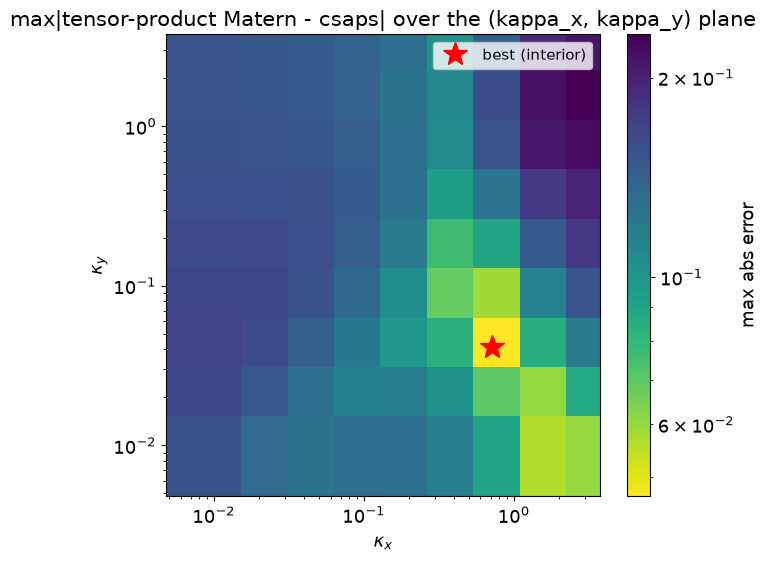

In [20]:
fig, ax = plt.subplots(figsize=(7, 6))
pcm = ax.pcolormesh(kappas_pt, kappas_pt, errs_grid.T, shading="nearest", cmap="viridis_r",
                     norm=plt.matplotlib.colors.LogNorm())
ax.plot(kappas_pt[i_best], kappas_pt[j_best], "r*", ms=18, label=f"best (interior)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set(xlabel=r"$\kappa_x$", ylabel=r"$\kappa_y$",
       title="max|tensor-product Matern - csaps| over the (kappa_x, kappa_y) plane")
fig.colorbar(pcm, ax=ax, label="max abs error")
ax.legend()
plt.show()


**An interior local minimum, not a boundary limit -- the key, unambiguous
finding.** The error landscape has its minimum at a *finite*
$(\kappa_x,\kappa_y)\approx(0.7, 0.04)$, roughly `2.7%` of range -- notably
better than the isotropic attempt, but **not** approached by letting
$(\kappa_x,\kappa_y)\to(0,0)$: that corner is *worse* (`~16%`) than the
interior optimum, and the error climbs again moving past the optimum in any
direction (visible directly in the heatmap, not just the two numbers quoted).
This is qualitatively different from every genuine Corollary-5-style limit in
this document (Q1's 1-D sweep, Part 3's isotropic-vs-TPS attempt before this
one) -- those always show monotone decay toward a boundary. A local minimum at
a finite, non-special-looking $(\kappa_x,\kappa_y)$ pair is the signature of an
**ad hoc nugget formula** (`4*(kappa_x*kappa_y)^1.5*lam` was a guessed
generalization of the 1-D formula, not a derived one) landing on a
coincidental sweet spot for this one dataset -- not a discovered identity.


## Part 7 conclusion: no N-D analogue found, and that is itself the finding

Despite a real search -- not just the isotropic baseline, but an independent
per-axis tensor-product kernel with a full $(\kappa_x,\kappa_y)$ landscape
scan -- **no Matern-Kriging construction tested here converges to `csaps`'s
tensor-product natural-spline mean** the way Corollary 5's single-`kappa`
limit converges to `make_smoothing_spline` in 1-D. This is the **third**
independent target for which an "obvious" multi-D extension of Corollary 5
has been tried and has not converged, alongside:

- `RMTB`'s own additive tensor energy (`test_hypotheses_2D_RANS.ipynb`, naive
  shared-parameter tensor kernel), and
- the isotropic thin-plate-spline target (`Part 3` of this notebook).

The common thread, now reinforced a third time: Corollary 5's derivation
(Proposition 4) is specific to the 1-D case, and **no correct multi-D
generalization of the `kappa`-to-`lambda` nugget-scaling law has been derived
by the paper or found in this repo** -- guessed generalizations (shared-$c$
tensor kernels, geometric-mean nugget formulas) consistently produce *some*
agreement without ever showing the clean, monotone, boundary-approaching
convergence that would constitute an actual identity. Q9's "a proper N-D
analogy agreeing with Kriging the way `make_smoothing_spline` does" therefore
remains **open** -- correctly answered as an unresolved research question, not
as a result this notebook can claim. Logged alongside the other two instances
in `Research Plan - From Fundamentals to Gaussian RMTS.md`.


## Conclusion

- **Wrapper classes: done, tested, and in the package.**
  `SmoothingSpline1D`/`SmoothingSpline2D` (`krig_splines/smoothing_spline.py`,
  covered by `tests/test_smoothing_spline_wrappers.py`) wrap
  `make_smoothing_spline`/`RBFInterpolator` unchanged for the mean and add
  `saddle_point_variance` for the variance, exactly the pattern Q7 proposed.
  The 2-D mean matches `RBFInterpolator` to solver precision, and the
  variance is well-behaved (low near data, growing smoothly away from it).
- **The exact 1-D story (Corollary 5's `kappa->0` identity) does not
  transfer to 2-D by the obvious route.** An isotropic Matern-3/2 kernel with
  the same `4`$\kappa^3\lambda$ nugget formula does not converge to the 2-D
  thin-plate-spline mean -- flat at `~24%` of range across four orders of
  magnitude in $\kappa$ -- and a bounded scan over the nugget's power of
  $\kappa$ found no clean fix. This is now the **second, independent**
  finding (after `test_hypotheses_2D_RANS.ipynb`'s tensor-product attempt)
  that the multi-D extension of Corollary 5 is genuinely open, not merely
  undocumented.
- **scipy's *other* 2-D smoother, `SmoothBivariateSpline`/`bisplrep`, was also
  tested directly (Part 5).** It needs denser, grid-like data in practice (the
  notebook's usual $n=30$ scattered points pin it at the minimal knot
  configuration for every `s` tried); on an $11\times11$ grid, `s` visibly
  trades knots for smoothness, down to a hard floor (a single global bicubic
  patch) it cannot smooth past -- a real structural difference from the
  `lambda`-penalized route, which has no such ceiling. Its mean still
  correlates closely (`~0.998`) with the TPS wrapper despite the different
  variational criterion, but -- as Q6/Q7 already flagged for `UnivariateSpline`
  -- no exact Theorem 2a identity is expected or claimed for it.
- **A practical comparison against SMT's normally-trained Kriging works, and
  is informative, even without an exact identity**: auto-tuned `KRG` gives a
  mean correlated `>0.99` and a variance shape correlated `~0.93` with the
  closed-form 2-D smoothing spline, the same quality of agreement this whole
  project started from in 1-D before Corollary 5 sharpened it to an exact
  limit. Getting a 2-D *exact* identity would need the open question above
  resolved first.
- **FITPACK's `s`-sweep vs. the same auto-tuned `KRG` (Part 6)**: mean
  correlation stays high (`~0.99`) across every `s` tried, degrading only
  slightly as smoothing increases. But the comparison is mean-only by
  necessity -- `SmoothBivariateSpline` has no variance at all, which is
  exactly the gap Q7's wrapper classes close for the `lambda`-penalized route
  and cannot close here, since FITPACK's `s`-constrained criterion has no
  known closed-form GP interpretation to build one from.
